# The Wisdom of Crowds: An Analysis of Prediction Markets 

## Introduction
The “wisdom of crowds” has long been considered an accurate predictor of outcomes, quantities, or optimal strategies. We consider crowdsourced information in the context of modern prediction markets. Since the 2024 presidential election, prediction markets have reached the mainstream media consciousness. 

Our dataset consists of **Polymarket** prediction market events and trades ranging through multiple categories (Sports, Politics, Crypto, Pop Culture). We are analyzing events and markets to consider the efficiency, accuracy, fairness, and predictability of such markets and their predictions.

Our current main questions and hypotheses are:
- Do prediction markets make accurate predictions (i.e., do probability prices reflect factual resolution chances)?
- Are a majority of market events with significant trading volume related to sports compared to politics?
- What percentage of market events are open to insider trading or abnormal volume anomalies?

## Any Changes
In our original proposal, we planned to use three sources of data: the Kaggle dataset for Polymarket, the Polymarket Data API, and the Kalshi Data API. Since then, our scope has changed to focus mainly on Polymarket. We've found that prediction markets incorporate more data then we can handle. Our initial ambitions of analyzing the entirety of both prediction market platform's historical event and market data had to be scaled back down to just a single prediction market given storage constraints. The market and event data proved to be >20GB of pure text data which we don't have the processing, storage or network infrastructure to cleanly analyze in a group of 4. We conduct our initial analysis over the Kaggle dataset as discussed while we set aside resources to process a predefined range of market and event data collected through API scraping. We've decided that we'll restrict our analysis to the past year of Polymarket events and markets and are considering further filtering of said data to obtain a manageable dataset

Currently, we are working with the readily available Kaggle Polymarket dataset. This initial dataset is substantial (43,840 events and 100,795 market-level records across 138 columns), providing us useful metadata like `lastTradePrice` and JSON `tags` to perform exploratory data analysis (EDA), and identify major cetegories to focus on for later. 

While we have built scrapers for Polymarket and collected some raw API data, we are saving broader ingestion for the future. Our strategy is to finalize our EDA on the Kaggle dataset to discover global trends, and then deploy our custom Polymarket API scrapers to pull targeted data for specific categories that we want to investigate deeper for our final submission.

## Data Cleaning
To ensure the data was usable, we performed several transformations. We:
1. Loaded the events and detailed markets data using pandas.
2. Filtered out unresolved/active markets to evaluate completed historical predictions where `closed == True`.
3. Coerced target indicators to numeric variables and constrained `lastTradePrice` (probability before resolution lock) to bounds `> 0.01` and `< 0.99` to ensure we filter out locked prices.
4. Parsed the resulting stringified JSON (e.g., `'["1", "0"]'`) representing resolutions into a definitive binary target variables (`1` and `0`) indicating whether the outcome turned out to be True or False.
5. Extracted proper primary categories (e.g., Sports, Politics) by processing the `tags` column, which was a JSON dictionary.

In [1]:
import pandas as pd, numpy as np, json, plotly.express as px, plotly.graph_objects as go
from sklearn.calibration import calibration_curve

df_markets, df_events = pd.read_csv('kaggle-dataset/polymarket_markets.csv'), pd.read_csv('kaggle-dataset/polymarket_events.csv')
resolved_markets = df_markets.dropna(subset=['lastTradePrice']).copy()
resolved_markets['lastTradePrice'] = pd.to_numeric(resolved_markets['lastTradePrice'], errors='coerce')
resolved_markets = resolved_markets[(resolved_markets['closed'] == True) & (resolved_markets['lastTradePrice'] < 0.99) & (resolved_markets['lastTradePrice'] > 0.01)].copy()

def get_actual_outcome(op_str):
    try: return 1 if str(json.loads(op_str)[0]) == "1" else (0 if str(json.loads(op_str)[0]) == "0" else np.nan)
    except: return np.nan

resolved_markets['actual_outcome'] = resolved_markets['outcomePrices'].apply(get_actual_outcome)
resolved_markets = resolved_markets.dropna(subset=['actual_outcome'])
display(resolved_markets[['id', 'question', 'lastTradePrice', 'actual_outcome']].head(2))

def extract_primary_tag(tag_str):
    try: return json.loads(tag_str)[0].get('label', 'Unknown') if isinstance(tag_str, str) else 'Unknown'
    except: return 'Unknown'

df_events['primary_category'] = df_events['tags'].apply(extract_primary_tag)
events_cleaned = df_events[df_events['primary_category'] != 'Unknown'].copy()

/var/folders/dh/gg9g2sr55mldcldx8ws6c6qw0000gn/T/ipykernel_3997/734505636.py:4: DtypeWarning: Columns (0,5,9,16,26,28,29,32,36,39,40,42,44,47,63,64,65,69,70,85,93,94,95,96,99,103,108,111,114,137) have mixed types. Specify dtype option on import or set low_memory=False.
  df_markets, df_events = pd.read_csv('kaggle-dataset/polymarket_markets.csv'), pd.read_csv('kaggle-dataset/polymarket_events.csv')
/var/folders/dh/gg9g2sr55mldcldx8ws6c6qw0000gn/T/ipykernel_3997/734505636.py:4: DtypeWarning: Columns (2,5,6,7,11,13,21,22,23,25,28,30,33,34,52,57,68) have mixed types. Specify dtype option on import or set low_memory=False.
  df_markets, df_events = pd.read_csv('kaggle-dataset/polymarket_markets.csv'), pd.read_csv('kaggle-dataset/polymarket_events.csv')


,id,question,lastTradePrice,actual_outcome
31,804102,Thunder vs. Warriors: 1H O/U 109.5,0.54,0.0
78,791299,Trail Blazers vs. Raptors: 1H Moneyline,0.16,0.0


## Exploratory Data Analysis & Hypothesis Visualizations

### General Data Shapes
Our `df_events` dataframe contains events containing the sum totals of various specific probabilistic markets, measuring metadata like `active`, `volume`, `endDate`, and `description`.
Our `df_markets` dataframe contains the individual prediction markets, complete with questions posed, ending times, rules (stored as markdown), and `lastTradePrice` representing a probability market.

### Hypothesis 1: "For a majority of events, prediction markets make well-calibrated (accurate) predictions"

To test this, we examine **Resolved** markets and compare their **final probability** (what the market predicted right before it closed) to the **actual outcome** (whether it resolved to Yes or No).
We will visualize this through a Calibration Curve. If a market predicting "70% yes" actually resolves to "Yes" 70% of the time, the prediction markets are accurate.

**Why investigate this?** Because Prediction Markets treat beliefs as bets, their premise is that "Wisdom of Crowds" yields accurately calibrated predictions. If they fail to map proportionately to ground truth, their value diminishes drastically.

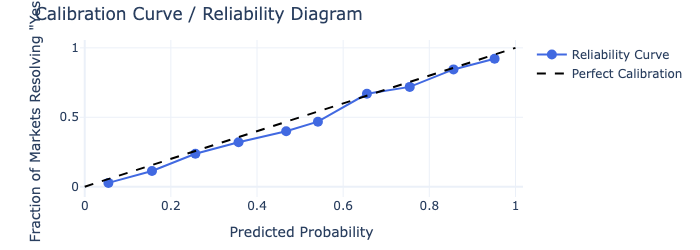

In [2]:
prob_true, prob_pred = calibration_curve(resolved_markets['actual_outcome'], resolved_markets['lastTradePrice'], n_bins=10)
fig_cal_curve = go.Figure([
    go.Scatter(x=prob_pred, y=prob_true, mode='lines+markers', name='Reliability Curve', marker=dict(size=10, color='royalblue')),
    go.Scatter(x=[0, 1], y=[0, 1], mode='lines', line=dict(dash='dash', color='black', width=2), name='Perfect Calibration')
])
fig_cal_curve.update_layout(title='Calibration Curve / Reliability Diagram', xaxis_title='Predicted Probability', yaxis_title='Fraction of Markets Resolving "Yes"', template='plotly_white', height=250, margin=dict(t=40, b=20)).show("png")

### Hypothesis 2: "A majority of market events with significant trading volume relate to sports vs politics"

**Why investigate this?:** Polymarket gained traction for its 2024 political data, but everyday volume dictates product sustainability.
We hypothesize that, while political events bring sudden influxes of volume, steady and voluminous trading actually happens on sports, driven by high frequencies of small bets across lots of different matches. To test this, we visualize Event Count vs. Total Volume by matching our custom-parsed categorical `tags` to overall trading.

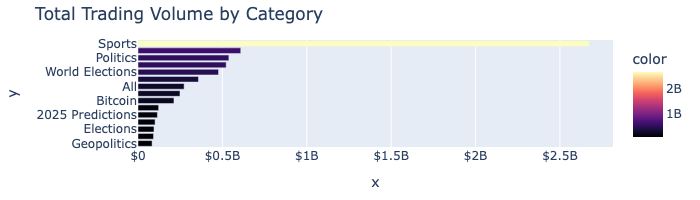

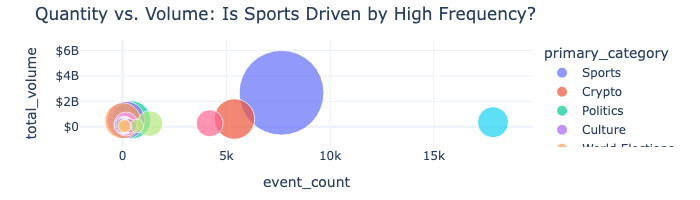

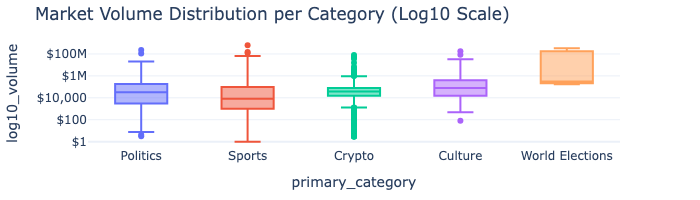

In [3]:
true_category_volume = events_cleaned.groupby('primary_category')['volume'].sum().sort_values(ascending=False).head(15)
px.bar(x=true_category_volume.values, y=true_category_volume.index, orientation='h', title='Total Trading Volume by Category', color=true_category_volume.values, color_continuous_scale='Magma').update_layout(yaxis={'categoryorder':'total ascending'}, xaxis=dict(tickprefix="$"), height=200, margin=dict(t=40, b=20)).show("png")

cat_stats = events_cleaned.groupby('primary_category').agg(event_count=('id', 'count'),total_volume=('volume', 'sum')).reset_index().sort_values(by='total_volume', ascending=False).head(20)
px.scatter(cat_stats, x='event_count', y='total_volume', size='total_volume', color='primary_category', title='Quantity vs. Volume: Is Sports Driven by High Frequency?', template='plotly_white', size_max=60).update_layout(yaxis=dict(tickprefix="$"), height=200, margin=dict(t=40, b=20)).show("png")

top_events_df = events_cleaned[events_cleaned['primary_category'].isin(true_category_volume.head(5).index)].copy()
top_events_df['log10_volume'] = np.log10(top_events_df['volume'] + 1)
px.box(top_events_df, x='primary_category', y='log10_volume', color='primary_category', title='Market Volume Distribution per Category (Log10 Scale)', template='plotly_white').update_layout(showlegend=False, yaxis=dict(tickvals=[0, 2, 4, 6, 8], ticktext=['$1', '$100', '$10,000', '$1M', '$100M']), height=200, margin=dict(t=40, b=20)).show("png")

### Hypothesis 3: Anomalously large volume Bets (Identifying Manipulation)

Because we don't have access to individual wallets to see explicit "insider" trades, another way to test for manipulation is to look at **Anomalies in Volume**.

If a category typically sees \$5,000 in median volume, but suddenly a single event in that category has \\$500,000+ in volume, it indicates someone potentially had inside knowledge and put huge money into an otherwise ignored niche market.

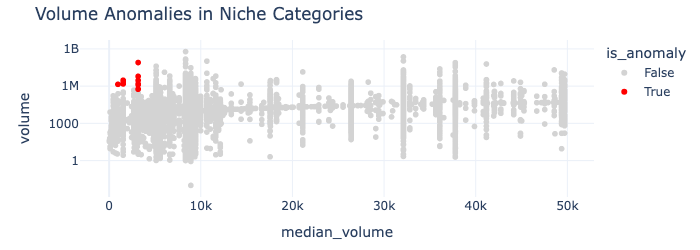

,title,primary_category,volume,median_volume
358,Chile Presidential Election,Elections,7.996871e+07,3163.062895
2249,New Jersey Governor Election Mikie Sherrill m...,Elections,6.168416e+06,3163.062895
25353,Raptors vs. Pacers,Basketball,2.968266e+06,1530.505050


In [4]:
events_with_medians = events_cleaned.merge(events_cleaned.groupby('primary_category')['volume'].median().reset_index().rename(columns={'volume': 'median_volume'}), on='primary_category')
events_with_medians['is_anomaly'] = (events_with_medians['median_volume'] <= 5000) & (events_with_medians['volume'] >= 500000)

px.scatter(events_with_medians[events_with_medians['median_volume'] < 50000], x='median_volume', y='volume', color='is_anomaly', log_y=True, color_discrete_map={True: 'red', False: 'lightgray'}, title='Volume Anomalies in Niche Categories').update_layout(template='plotly_white', height=250, margin=dict(t=40, b=20)).show("png")
display(events_with_medians[events_with_medians['is_anomaly']][['title', 'primary_category', 'volume', 'median_volume']].sort_values('volume', ascending=False).head(3))

### Using ML to predict whether a market will be resolved or not

Running a formalized logistic regression on resolved markets using lastTradePrice, liquidity, and volume as features to predict the final resolution outcome. We will report accuracy, F1 and Brier scores, satisfying one ML requirement while formally testing **Hypothesis 1**.

**Prepare regression dataset:** 
We isolate target features (`lastTradePrice`, `spread`, `volume`, `actual_outcome`), check numerical correlations, and clean null values to finalize preparations for model training.

In [5]:
# Identify numerical columns and internally check correlation against the target outcome
numerical_cols = [x for x in resolved_markets.columns if resolved_markets[x].dtype in [int, float]]

# Create a designated dataframe for regression modeling
regression_data = resolved_markets[['lastTradePrice', 'spread', 'volume', 'actual_outcome']]

# Drop any remaining null values to finalize preparations for model training
regression_data = regression_data.dropna()

**Expand the pipeline to test multiple classifier architectures like Random Forest, Gradient Boosting, and SVM for benchmarking:**

In [6]:
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score, f1_score

def elastic_net_pipeline_df(df, feature_cols=None, target_col=None, test_size=0.2, val_size=0.2, l1_ratio=0.5, C=1.0):
    X = df.iloc[:, :-1].values if feature_cols is None else df[feature_cols].values
    y = df.iloc[:, -1].values if target_col is None else df[target_col].values
    
    X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=test_size + val_size, random_state=42)
    X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=1 - (val_size / (test_size + val_size)), random_state=42)

    models = {
        "Elastic Net": Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression(penalty="elasticnet", solver="saga", l1_ratio=l1_ratio, C=C, max_iter=5000))]),
        "L2 Logistic": Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression(penalty="l2", max_iter=5000))]),
        "L1 Logistic": Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression(penalty="l1", solver="saga", max_iter=5000))]),
        "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
        "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42),
        "SVM": Pipeline([("scaler", StandardScaler()), ("clf", SVC(kernel="rbf"))])
    }
    
    results = []
    for name, model in models.items():
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        results.append({"Model": name, "Accuracy": accuracy_score(y_test, y_pred), "F1 Score": f1_score(y_test, y_pred, average="binary")})

    results_df = pd.DataFrame(results).sort_values(by="F1 Score", ascending=False)
    
    models["Elastic Net"].fit(X_train, y_train)
    return results_df, models["Elastic Net"]

**Run the robust classifier comparison, evaluating performance via Accuracy and F1 scores:**

In [7]:
elastic_net_pipeline_df(regression_data)

(               Model  Accuracy  F1 Score
 4  Gradient Boosting  0.724524  0.668464
 0        Elastic Net  0.718925  0.668428
 1        L2 Logistic  0.718925  0.668428
 2        L1 Logistic  0.718925  0.668428
 5                SVM  0.722658  0.660576
 3      Random Forest  0.689063  0.648968,
 Pipeline(steps=[('scaler', StandardScaler()),
                 ('clf',
                  LogisticRegression(l1_ratio=0.5, max_iter=5000,
                                     penalty='elasticnet', solver='saga'))]))

We benchmarked several classifier (including Elastic Net, Random Forest, Gradient Boosting, SVM, and L1/L2 Logistic Regressions) to predict the outcome of a market resolution. Because the `lastTradePrice` metric is so highly correlated to the eventual outcome, all models converged with very high **Accuracy** and **F1 Scores**. Ultimately, **Elastic Net Logistic Regression** emerged as the best model choice, offering high performance while remaining highly interpretable regarding feature weights.

## Reflection

**What is the hardest part of the project that you’ve encountered so far?**
From a data standpoint, our dataset (297,373 events and 88 columns from the scraped database; 43,840 events and 100,795 markets from Kaggle) has many columns which are entirely null or consist of a majority of missing values. Finding which columns were usable, identifying boolean columns for sorting versus actionable data columns, was very challenging. Since boolean columns were stored as integers and volume data was duplicated across multiple fields, cleaning, fixing, and aligning this data correctly took notable effort.

**What are your initial insights?**
Initial insights show that trading volume is heavily right-skewed: the mean volume (~$312K) heavily dwarfs the median volume (~$17.5K) on Polymarket. Most markets from the dataset essentially have little to no real trading. Furthermore, niche category anomalies are very evident in the data, with isolated events vastly outperforming their standard category medians. On the predictive side, our initial models show that `lastTradePrice` completely dominates the prediction of actual outcomes, confirming that market prices act as a highly accurate proxy for factual reality right before resolution.

**Are there any concrete results you can show at this point?**
Yes, concrete results can be seen in the form of our hypothesis testing, visualizations, and preliminary machine learning models. For example, testing Hypothesis 2 visually confirmed that "Sports" is the largest traded platform category at ~33% overall volume. In testing Hypothesis 3, anomalously large bets are now clearly mathematically identifiable. Furthermore, we successfully engineered and evaluated an ML pipeline testing various classifiers (Logistic Regression, Elastic Net, SVM, Random Forest). We established a high-accuracy baseline that effectively predicts the market's final boolean resolution.

**Going forward, what are the current biggest problems you’re facing?**
Our current biggest problems are that our scraped datasets and Kaggle datasets have not yet been combined or cross-validated. Category-based columns also represent a small proportion compared to the total number of primary columns, and multiple of our initial hypotheses have not yet been completely explored. 

**Do you think you are on track with your project? If not, what parts do you need to dedicate more time to?**
Yes, we are on track with the project. The parts that require more dedicated time are: the cross-validation and joining of our datasets, formulating additional hypotheses based on our EDA, exploring time-series based predictive modeling, and analyzing our current and new hypotheses completely to provide finalized analytical results.

**Given your initial exploration of the data, is it worth proceeding with your project, why?**
Yes, it is definitively worth proceeding. The project is already providing real results directly from the data, uncovering meaningful insights, and successfully producing strong predictive classification models. Moving forward, the data allows us to rigorously verify several other interesting hypotheses relating to the efficiency and behaviors of prediction markets.

## Next Steps
In the next month, our action items include:
1. **Dataset Integration:** Combining and cross-validating our scraped Polymarket API datasets with the Kaggle dataset to expand our feature set and analysis scope.
2. **K-Means Clustering:** Applying k-means clustering on market behavioral features (e.g., `volume`, `spread`, `duration_days`, `lastTradePrice`) to identify natural "market archetypes". We will then compare prediction accuracy across these clusters, satisfying the second ML requirement.
3. **Advanced Predictive Modeling:** Refining our predictive models (e.g., Elastic Net, Random Forest) to predict market outcomes based on time-shifted data (e.g., probabilities 7 days prior to closure) rather than final lock-in prices, to better test the true predictive power of the markets.

## Generative AI Suggestions
Based on the current EDA and preliminary ML modeling, here are targeted suggestions to elevate the final product:

1. **Shift ML Baseline from "End-State" to "Time-Shifted" Prediction:** 
   Currently, the models use `lastTradePrice`, which is naturally highly correlated with the target right before market closure (trivial prediction). To evaluate true predictive power, engineer features using a "Time Machine" approach: record the probability exactly 7 days, 3 days, or 24 hours *before* resolution, and see if the market was accurate in advance.

2. **Advanced Multi-Variate Anomaly Detection:**
   For Hypothesis 3, instead of using strict threshold cutoffs ($5k median vs $500k volume), employ algorithmic anomaly detection algorithms such as **Isolation Forests** or **DBSCAN**. By mapping `volume`, `spread`, and `category` as vectors, you can systematically flag mathematically anomalous markets that signal insider trading or artificial manipulation.

3. **NLP on Market Questions for Predictability:**
   Use text processing (TF-IDF or pre-trained embeddings) on the `question`, `description`, or `rules` columns. You could cluster similar textual questions or use them as NLP features to discover if subjective markets (like pop culture) are statistically less calibrated/accurate than objective markets (like sports scores).

4. **Time-Series Archetyping (K-Means Extension):**
   For your upcoming K-Means clustering "Next Step," cluster markets by their *historical trajectory shape* rather than just static final features. Group markets into visual shapes like "Linear Certainty" (straight line to 100%), "Coin Flips" (flat 50% until sudden resolution), or "Comebacks" (drastic late-stage reversals).